# 23 · Regret of choosing one system versus pairing two (post hoc)

**Status: post hoc, exploratory, requested in the discussion of review cycle 1.** Reads only frozen prediction files and changes no locked result. Writes aggregates and a per-pair table of model names and counts (no image or patient identifiers).

**Question.** A programme has two candidate systems and does not know which is stronger on its own patients. How much worse than the better of the two (with hindsight) does it do if it:
1. **picks one blind** (expected regret is half the gap between the two; the worst case is the whole gap);
2. **picks one using a small local pilot**: k cases with the target disease and k without, drawn from whole patients, choosing the system with the higher AUC; those patients are then excluded and the regret is scored on the rest (k = 25, 50, 100);
3. **picks one using half of its own patients** (the system with fewer misses on that half; scored on the other half; 50 random splits, both directions);
4. **runs both as a pair** at the same referral share (maximum-rank rule)?

Regret is missed cases per 10,000 images above the better member. Zero means as good as knowing in advance which system is stronger; negative means better than that.

**Rosters and outcomes.**
- EyePACS, DDR and BRSET: the main roster (11 designs × 3 runs, 55 design pairs × 9 run combinations), severe DR (grade 3 or 4); DDR also PDR, its locked outcome.
- BRSET mixed-source: the four 5-class designs trained on EyePACS and on DDR (24 systems), all pairs except repeat runs of one system, labelled by training source. This shows what happens when the two candidates differ a lot in strength.
- HIBA and PAD-UFES-20: 66 variant pairs × 4 run combinations, melanoma and any skin cancer, labelled same or different training collection.

**Runtime:** CPU, about 30 to 45 minutes.

In [1]:
from google.colab import drive
drive.mount("/content/drive")
import os, re, json, hashlib, itertools, datetime, time, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
DATA = "/content/drive/MyDrive/stochastic_orthogonality/data"
BASE = f"{DATA}/dr_ensemble_v2"; PREDS, SPLITS = f"{BASE}/03_predictions", f"{BASE}/01_splits"
BRSET_LABELS = f"{DATA}/brset/label_brset.csv"; DERM = f"{DATA}/derm"
OUTD = f"{BASE}/04_results/revisions_c1"; os.makedirs(OUTD, exist_ok=True)
OUT_JSON, OUT_CSV = f"{OUTD}/regret_c1.json", f"{OUTD}/regret_c1_pairs.csv"
assert not os.path.exists(OUT_JSON), "already written; rename the old output deliberately to rerun"
B, SEED, DRAWS, NSPLIT, KPILOT = 1000, 20261030, 100, 50, (25, 50, 100)
def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
def refer(s, f):
    r = np.zeros(len(s), bool); r[np.argsort(-s, kind="stable")[:int(round(f * len(s)))]] = True; return r
def rk(s): return rankdata(s) / len(s)
def pairscore(ra, rb): return np.maximum(ra, rb) + 1e-9 * np.minimum(ra, rb)
def boot_w(groups, n_boot, seed):
    codes = pd.factorize(groups)[0]; G = codes.max() + 1; rng = np.random.default_rng(seed)
    W = np.empty((n_boot + 1, len(codes)), np.float32); W[0] = 1.0
    for b in range(1, n_boot + 1): W[b] = np.bincount(rng.integers(0, G, G), minlength=G)[codes]
    return W
def ci(x):
    x = np.asarray(x, float); f = x[1:][np.isfinite(x[1:])]
    return [float(x[0]), float(np.percentile(f, 2.5)), float(np.percentile(f, 97.5))]
def ci_basic(x):
    x = np.asarray(x, float); f = x[1:][np.isfinite(x[1:])]
    return [float(x[0]), float(2 * x[0] - np.percentile(f, 97.5)), float(2 * x[0] - np.percentile(f, 2.5))]
def pct(x): x = np.asarray(x, float); return [float(np.mean(x)), float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5))]
def fmt(t, d=2): return f"{t[0]:.{d}f} ({t[1]:.{d}f} to {t[2]:.{d}f})"
def pick(cols, pats, what):
    m = [c for c in cols if any(re.fullmatch(p, c, flags=re.I) for p in pats)]
    assert len(m) == 1, f"cannot identify the {what} column; columns are {list(cols)}"
    return m[0]
def norm(x): return pd.Series(x, dtype=str).str.replace(r"\.(jpe?g|png|tiff?)$", "", regex=True, flags=re.I).to_numpy()
HASHES = {}
print("ready")

Mounted at /content/drive
ready


## 1. Load frozen predictions

In [2]:
ARCHS = ["densenet121_binary", "densenet121_5class", "efficientnet_b3_binary", "efficientnet_b3_5class", "resnet50_binary", "resnet50_5class",
         "vit_base_binary", "vit_base_5class", "retfound_binary", "retfound_5class", "retfound_adversarial"]
CORE4 = ["densenet121_5class", "efficientnet_b3_5class", "resnet50_5class", "retfound_5class"]
RSEEDS = [0, 1, 2]; RMODELS = [(a, k) for a in ARCHS for k in RSEEDS]
def tag(k): return "" if k == 0 else f"_seed{k}"
def load_preds(fmt_):
    P = {}; ref = None
    for a, k in RMODELS:
        fn = f"{PREDS}/{fmt_.format(arch=a, tag=tag(k))}"; HASHES[os.path.basename(fn)] = sha(fn)
        d = pd.read_csv(fn, dtype={"image_id": str})
        if ref is None: ref = d
        else: assert (d.image_id.values == ref.image_id.values).all(), fn
        P[(a, k)] = d["predicted_probability"].to_numpy(np.float64)
    return ref, P
RET = {}
ref, P = load_preds("eyepacs_predictions_fresh_{arch}{tag}_v2.csv")
RET["EyePACS"] = {"grade": ref.true_grade.to_numpy(int), "group": ref.patient_id.astype(str).to_numpy(), "P": P, "f": 0.25}
ref, P = load_preds("ddr_predictions_{arch}{tag}_v2.csv")
sp = pd.read_csv(f"{SPLITS}/ddr_split_intraset_v2.csv", dtype={"image_id": str})
gcol, grpcol = pick(sp.columns, ["grade", "true_grade", "dr_grade", "level"], "DDR grade"), pick(sp.columns, ["group", "filename_group", "group_id"], "DDR group")
sp["_k"] = norm(sp["image_id"]); sp = sp.set_index("_k").loc[norm(ref.image_id)]
g = sp[gcol].to_numpy(int); keep = g <= 4; isA = sp["half"].astype(str).str.upper().eq("A").to_numpy() if "half" in sp.columns else np.ones(len(g), bool)
RET["DDR"] = {"grade": g[keep], "group": sp[grpcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}, "f": round(1.31 * float((g[keep & isA] >= 2).mean()), 4)}
ref, P = load_preds("brset_predictions_eyepacs_{arch}{tag}_v2.csv")
lb = pd.read_csv(BRSET_LABELS, dtype=str)
icol, pcol, idcol = pick(lb.columns, [r".*icdr.*"], "BRSET ICDR grade"), pick(lb.columns, ["patient_id", "patient"], "BRSET patient"), pick(lb.columns, ["image_id", "image"], "BRSET image id")
lb["_k"] = norm(lb[idcol]); lb = lb.set_index("_k").loc[norm(ref.image_id)]
g = pd.to_numeric(lb[icol], errors="coerce").to_numpy(); keep = np.isin(g, [0, 1, 2, 3, 4])
RET["BRSET"] = {"grade": g[keep].astype(int), "group": lb[pcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}}
RET["BRSET"]["f"] = round(1.31 * float((RET["BRSET"]["grade"] >= 2).mean()), 4)
PB = {}
for src in ("eyepacs", "ddr"):
    for a in CORE4:
        for k in RSEEDS:
            fn = f"{PREDS}/brset_predictions_{src}_{a}{tag(k)}_v2.csv"; HASHES[os.path.basename(fn)] = sha(fn)
            d = pd.read_csv(fn, dtype={"image_id": str}); assert (norm(d.image_id) == lb.index.to_numpy()).all(), fn
            PB[(src, a, k)] = d["predicted_probability"].to_numpy(np.float64)[keep]
for n_, d in RET.items(): print(f"{n_:>8}: {len(d['grade']):,} images | {len(set(d['group'])):,} groups | f = {d['f']}")
# skin
CLASSES = ["MEL", "BCC", "SCC", "AK", "NV", "BKL", "DF", "VASC"]; SARCHS = ["resnet50", "densenet121", "efficientnet_b3", "convnext_t", "vit_b", "vit_b_dinov2"]
SOURCES = ["HAM10000", "BCN20000"]; SMODELS = [(s, a, k) for s in SOURCES for a in SARCHS for k in (0, 1)]; VARIANTS = [(s, a) for s in SOURCES for a in SARCHS]
SKIN = {}
for es in ("HIBA", "PAD"):
    D = pd.read_csv(f"{DERM}/manifest_{es}.csv", dtype={"image_id": str, "patient_id": str}).sort_values("image_id")
    D = D[~D.duplicated("raw_sha256", keep="first") & D.dx.isin(CLASSES)].reset_index(drop=True); P = {}
    for m in SMODELS:
        fn = f"{DERM}/predictions/{es}__{m[0]}_{m[1]}_seed{m[2]}.csv"; HASHES[os.path.basename(fn)] = sha(fn)
        p = pd.read_csv(fn, dtype={"image_id": str}).drop_duplicates("image_id").set_index("image_id").reindex(D.image_id); assert p.p_malignant.notna().all(); P[m] = p.p_malignant.to_numpy()
    dx = D.dx.to_numpy(); mal = np.isin(dx, ["MEL", "BCC", "SCC"])
    SKIN[es] = {"dx": dx, "mal": mal, "mel": dx == "MEL", "group": D.patient_id.astype(str).fillna("none").to_numpy(), "P": P, "f": round(1.31 * float(mal.mean()), 4)}
    print(f"{es:>8}: {len(dx):,} images | {len(set(SKIN[es]['group'])):,} patients | f = {SKIN[es]['f']}")

 EyePACS: 15,794 images | 7,897 groups | f = 0.25
     DDR: 12,422 images | 332 groups | f = 0.555
   BRSET: 16,266 images | 8,524 groups | f = 0.0745
    HIBA: 1,616 images | 623 patients | f = 0.6088
     PAD: 2,283 images | 1,373 patients | f = 0.6203


## 2. Rosters

In [3]:
def mname(m): return "_".join(str(x) for x in m)
ROSTERS = []
main_pairs = [((a, i), (b, j), "main roster") for a, b in itertools.combinations(ARCHS, 2) for i in RSEEDS for j in RSEEDS]
for pop in ("EyePACS", "DDR", "BRSET"):
    d = RET[pop]
    ROSTERS.append({"key": f"{pop}_severe", "label": f"{pop}, severe DR", "y": d["grade"] >= 3, "group": d["group"], "P": d["P"], "pairs": main_pairs, "f": d["f"]})
ROSTERS.append({"key": "DDR_pdr", "label": "DDR, PDR", "y": RET["DDR"]["grade"] == 4, "group": RET["DDR"]["group"], "P": RET["DDR"]["P"], "pairs": main_pairs, "f": RET["DDR"]["f"]})
def src_type(a, b):
    if a[0] == b[0]: return f"both {'EyePACS' if a[0] == 'eyepacs' else 'DDR'}-trained"
    return "one of each"
mixed_pairs = [(a, b, src_type(a, b)) for a, b in itertools.combinations(PB, 2) if a[:2] != b[:2]]
ROSTERS.append({"key": "BRSET_mixed_severe", "label": "BRSET, mixed training sources, severe DR", "y": RET["BRSET"]["grade"] >= 3, "group": RET["BRSET"]["group"], "P": PB, "pairs": mixed_pairs, "f": RET["BRSET"]["f"]})
skin_pairs = [((*va, i), (*vb, j), "same collection" if va[0] == vb[0] else "different collection") for va, vb in itertools.combinations(VARIANTS, 2) for i in (0, 1) for j in (0, 1)]
for es in ("HIBA", "PAD"):
    S = SKIN[es]
    for oname, y in (("melanoma", S["mel"]), ("any skin cancer", S["mal"])):
        ROSTERS.append({"key": f"{es}_{'mel' if oname == 'melanoma' else 'mal'}", "label": f"{es}, {oname}", "y": y, "group": S["group"], "P": S["P"], "pairs": skin_pairs, "f": S["f"]})
for R_ in ROSTERS: print(f"{R_['key']:22s} pairs {len(R_['pairs']):4d} | cases {int(R_['y'].sum()):5d} | f {R_['f']}")

EyePACS_severe         pairs  495 | cases   712 | f 0.25
DDR_severe             pairs  495 | cases  1149 | f 0.555
BRSET_severe           pairs  495 | cases   474 | f 0.0745
DDR_pdr                pairs  495 | cases   913 | f 0.555
BRSET_mixed_severe     pairs  252 | cases   474 | f 0.0745
HIBA_mel               pairs  264 | cases   253 | f 0.6088
HIBA_mal               pairs  264 | cases   751 | f 0.6088
PAD_mel                pairs  264 | cases    52 | f 0.6203
PAD_mal                pairs  264 | cases  1081 | f 0.6203


## 3. Regret on the full sample (blind pick and pair)
For each pair, both members and the pair refer the same share f. The better member is chosen in each bootstrap resample. Blind-pick regret is |A − B| / 2 (expected) and |A − B| (worst case); pair regret is pair − min(A, B); downside protection is max(A, B) − pair. Intervals resample patients (DDR: filename groups). Pair regret and downside protection use percentile intervals, as for the locked results. Blind-pick regret is a gap between two estimates, whose bootstrap distribution is biased upward (noise always widens a gap), so it uses the basic bootstrap interval, which corrects for that shift.

In [4]:
RES, ROWS = {}, []
for R_ in ROSTERS:
    t0 = time.time(); y, P, f = R_["y"], R_["P"], R_["f"]; W = boot_w(R_["group"], B, SEED); Wt = W.sum(1, dtype=np.float64)
    used = sorted({m for a, b, _ in R_["pairs"] for m in (a, b)}, key=str)
    REF = {m: refer(P[m], f) for m in used}; K = {m: rk(P[m]) for m in used}; MV = {m: W @ (y & ~REF[m]).astype(np.float32) for m in used}
    acc = {}
    for a, b, t in R_["pairs"]:
        pv = W @ (y & ~refer(pairscore(K[a], K[b]), f)).astype(np.float32); A_, B_ = MV[a], MV[b]; lo, hi = np.minimum(A_, B_), np.maximum(A_, B_)
        v = {"pair_regret": (pv - lo) / Wt * 1e4, "blind_expected_regret": (hi - lo) / 2 / Wt * 1e4, "blind_worst_regret": (hi - lo) / Wt * 1e4, "gain_vs_worse_member": (hi - pv) / Wt * 1e4}
        for grp in ("all", t):
            for kk, vv in v.items(): acc.setdefault(grp, {}).setdefault(kk, []).append(vv)
        ROWS.append({"roster": R_["key"], "pair_type": t, "system_a": mname(a), "system_b": mname(b), "misses_a": int(A_[0]), "misses_b": int(B_[0]), "misses_pair": int(pv[0]),
                     "gap_per_10k": float((hi - lo)[0] / Wt[0] * 1e4), "pair_regret_per_10k": float(v["pair_regret"][0])})
    out = {"label": R_["label"], "pairs": len(R_["pairs"]), "cases": int(y.sum()), "images": int(len(y)), "f": f}
    for grp, dd in acc.items():
        o = {k: (ci_basic if k.startswith("blind") else ci)(np.mean(vv, 0)) for k, vv in dd.items()}
        pr, gp = np.array([x[0] for x in dd["pair_regret"]]), np.array([x[0] for x in dd["blind_worst_regret"]])
        o.update({"n_pairs": len(pr), "pair_regret_median": float(np.median(pr)), "pair_regret_p90": float(np.percentile(pr, 90)), "pair_regret_max": float(pr.max()),
                  "blind_worst_regret_max": float(gp.max()), "share_pairs_pair_beats_blind_pick": float(np.mean(pr < gp / 2)), "share_pairs_pair_at_or_below_better_member": float(np.mean(pr <= 0))})
        out[grp] = o
    RES[R_["key"]] = {"full_sample": out}
    a_ = out["all"]
    print(f"{R_['key']:22s} ({time.time() - t0:.0f}s) blind pick {fmt(a_['blind_expected_regret'])} | pair {fmt(a_['pair_regret'])} | vs worse {fmt(a_['gain_vs_worse_member'])}"
          f" | pair beats blind pick in {a_['share_pairs_pair_beats_blind_pick']:.0%} of pairs | worst blind {a_['blind_worst_regret_max']:.1f} vs worst pair {a_['pair_regret_max']:.1f}")
    for grp in out:
        if isinstance(out[grp], dict) and grp != "all": print(f"    {grp:22s} blind {fmt(out[grp]['blind_expected_regret'])} | pair {fmt(out[grp]['pair_regret'])} | n {out[grp]['n_pairs']}")
PAIRS_DF = pd.DataFrame(ROWS)

EyePACS_severe         (3s) blind pick 3.79 (2.26 to 4.66) | pair -3.00 (-3.97 to -1.46) | vs worse 10.57 (8.29 to 13.18) | pair beats blind pick in 99% of pairs | worst blind 22.8 vs worst pair 5.7
    main roster            blind 3.79 (2.26 to 4.66) | pair -3.00 (-3.97 to -1.46) | n 495
DDR_severe             (2s) blind pick 6.92 (2.93 to 9.70) | pair -3.79 (-5.59 to -1.51) | vs worse 17.62 (10.62 to 25.99) | pair beats blind pick in 99% of pairs | worst blind 42.7 vs worst pair 7.2
    main roster            blind 6.92 (2.93 to 9.70) | pair -3.79 (-5.59 to -1.51) | n 495
BRSET_severe           (3s) blind pick 11.40 (8.92 to 13.55) | pair 1.83 (0.14 to 3.67) | vs worse 20.96 (16.91 to 25.20) | pair beats blind pick in 98% of pairs | worst blind 89.1 vs worst pair 19.1
    main roster            blind 11.40 (8.92 to 13.55) | pair 1.83 (0.14 to 3.67) | n 495
DDR_pdr                (2s) blind pick 6.93 (3.00 to 9.75) | pair -3.04 (-4.74 to -0.91) | vs worse 16.91 (9.70 to 25.30) | pair 

## 4. Picking one system with local data
**Pilot.** For each draw, patients with the target disease are taken in random order until k target images are available, and patients without it until k other images are available. The system with the higher AUC on those 2k images is chosen (a tie counts as a blind pick). Every image of the drawn patients is excluded; on the remaining images every system's and pair's referrals are rebuilt at share f and regret is scored there. A pilot size is skipped when the set has fewer than 2k target images. **Half split.** Patients are split in half at random; the system with fewer misses on one half (referrals rebuilt within that half) is chosen and scored on the other half, both directions. Values are means over pairs; intervals are the 2.5th and 97.5th percentiles across draws or splits.

In [5]:
def eval_set(R_, ev):
    y, P, f = R_["y"][ev], R_["P"], R_["f"]; used = sorted({m for a, b, _ in R_["pairs"] for m in (a, b)}, key=str)
    K = {m: rk(P[m][ev]) for m in used}; M = {m: int((y & ~refer(P[m][ev], f)).sum()) for m in used}
    PM = {(a, b): int((y & ~refer(pairscore(K[a], K[b]), f)).sum()) for a, b, _ in R_["pairs"]}
    return M, PM, ev.sum()
def regrets(R_, M, PM, n, choose):
    out = {}
    for a, b, t in R_["pairs"]:
        lo = min(M[a], M[b]); c = choose(a, b)
        ch = M[a] if c == 1 else (M[b] if c == -1 else 0.5 * (M[a] + M[b]))
        for grp in ("all", t):
            o = out.setdefault(grp, {"pick": [], "pair": [], "blind": []})
            o["pick"].append((ch - lo) / n * 1e4); o["pair"].append((PM[(a, b)] - lo) / n * 1e4); o["blind"].append((abs(M[a] - M[b]) / 2) / n * 1e4)
    return {g: {k: float(np.mean(v)) for k, v in o.items()} for g, o in out.items()}
for R_ in ROSTERS:
    t0 = time.time(); y = R_["y"]; pid = pd.factorize(R_["group"])[0]; npat = pid.max() + 1; P = R_["P"]
    used = sorted({m for a, b, _ in R_["pairs"] for m in (a, b)}, key=str)
    tpat = np.unique(pid[y]); opat = np.setdiff1d(np.arange(npat), tpat); rng = np.random.default_rng(SEED + 1); pilot = {}
    for k in KPILOT:
        if y.sum() < 2 * k: continue
        draws = []; npt = []
        for _ in range(DRAWS):
            cs, ni = [], 0
            for p_ in rng.permutation(tpat):
                cs.append(p_); ni += int((y & (pid == p_)).sum())
                if ni >= k: break
            cn, nj = [], 0
            for p_ in rng.permutation(opat):
                cn.append(p_); nj += int((pid == p_).sum())
                if nj >= k: break
            si = rng.permutation(np.flatnonzero(y & np.isin(pid, cs)))[:k]; ni_ = rng.permutation(np.flatnonzero(np.isin(pid, cn)))[:k]
            cal = np.r_[si, ni_]; ycal = np.r_[np.ones(len(si)), np.zeros(len(ni_))]; auc = {m: roc_auc_score(ycal, P[m][cal]) for m in used}
            ev = ~np.isin(pid, np.r_[cs, cn]); M, PM, n = eval_set(R_, ev); npt.append(len(cs))
            draws.append(regrets(R_, M, PM, n, lambda a, b: int(np.sign(auc[a] - auc[b]))))
        pilot[k] = {g: {kk: pct([d_[g][kk] for d_ in draws]) for kk in draws[0][g]} for g in draws[0]}; pilot[k]["patients_with_target_drawn"] = float(np.mean(npt))
    half = []
    for s in range(NSPLIT):
        hm = (rng.permutation(npat) < npat // 2)[pid]
        for cm_, em_ in ((hm, ~hm), (~hm, hm)):
            Mc = {m: int((y[cm_] & ~refer(P[m][cm_], R_["f"])).sum()) for m in used}; M, PM, n = eval_set(R_, em_)
            half.append(regrets(R_, M, PM, n, lambda a, b: int(np.sign(Mc[b] - Mc[a]))))
    RES[R_["key"]]["pilot"] = pilot
    RES[R_["key"]]["half_split"] = {g: {kk: pct([d_[g][kk] for d_ in half]) for kk in half[0][g]} for g in half[0]}
    hs = RES[R_["key"]]["half_split"]["all"]
    print(f"{R_['key']:22s} ({time.time() - t0:.0f}s) " + " | ".join(f"pilot {k}: pick {fmt(v['all']['pick'])}, pair {fmt(v['all']['pair'])}" for k, v in pilot.items())
          + f" | half split: pick {fmt(hs['pick'])}, pair {fmt(hs['pair'])}, blind {fmt(hs['blind'])}")

EyePACS_severe         (300s) pilot 25: pick 2.93 (0.81 to 6.09), pair -2.91 (-3.07 to -2.68) | pilot 50: pick 2.31 (0.67 to 5.69), pair -2.84 (-3.09 to -2.47) | pilot 100: pick 1.61 (0.45 to 4.10), pair -2.63 (-2.99 to -2.11) | half split: pick 1.21 (0.58 to 2.18), pair -2.69 (-4.04 to -1.40), blind 4.12 (3.11 to 5.33)
DDR_severe             (217s) pilot 25: pick 5.11 (1.58 to 9.95), pair -3.55 (-3.82 to -3.11) | pilot 50: pick 4.38 (1.45 to 9.23), pair -3.48 (-3.83 to -3.01) | pilot 100: pick 3.32 (0.93 to 7.42), pair -3.23 (-3.72 to -2.69) | half split: pick 1.69 (0.70 to 2.84), pair -3.07 (-5.11 to -0.95), blind 7.32 (4.47 to 10.74)
BRSET_severe           (306s) pilot 25: pick 3.53 (0.84 to 10.29), pair 1.81 (1.47 to 2.17) | pilot 50: pick 2.48 (0.53 to 7.63), pair 1.94 (1.43 to 2.43) | pilot 100: pick 1.24 (0.32 to 2.81), pair 1.74 (1.12 to 2.33) | half split: pick 0.60 (0.27 to 1.33), pair 2.03 (0.26 to 3.70), blind 11.69 (9.59 to 13.81)
DDR_pdr                (219s) pilot 25: pi

## 5. Figures
**a.** Each dot is one pair: the gap between its two members (x) against the pair's regret (y), per 10,000 images. Dots below the dashed line (half the gap) beat a blind pick on average; dots below zero beat even knowing which member is stronger. **b.** Mean regret by strategy, lower is better; zero is the performance of the better member chosen with hindsight. Blind pick and pair: patient bootstrap 95% intervals; local picks: 2.5th to 97.5th percentiles across draws or splits.

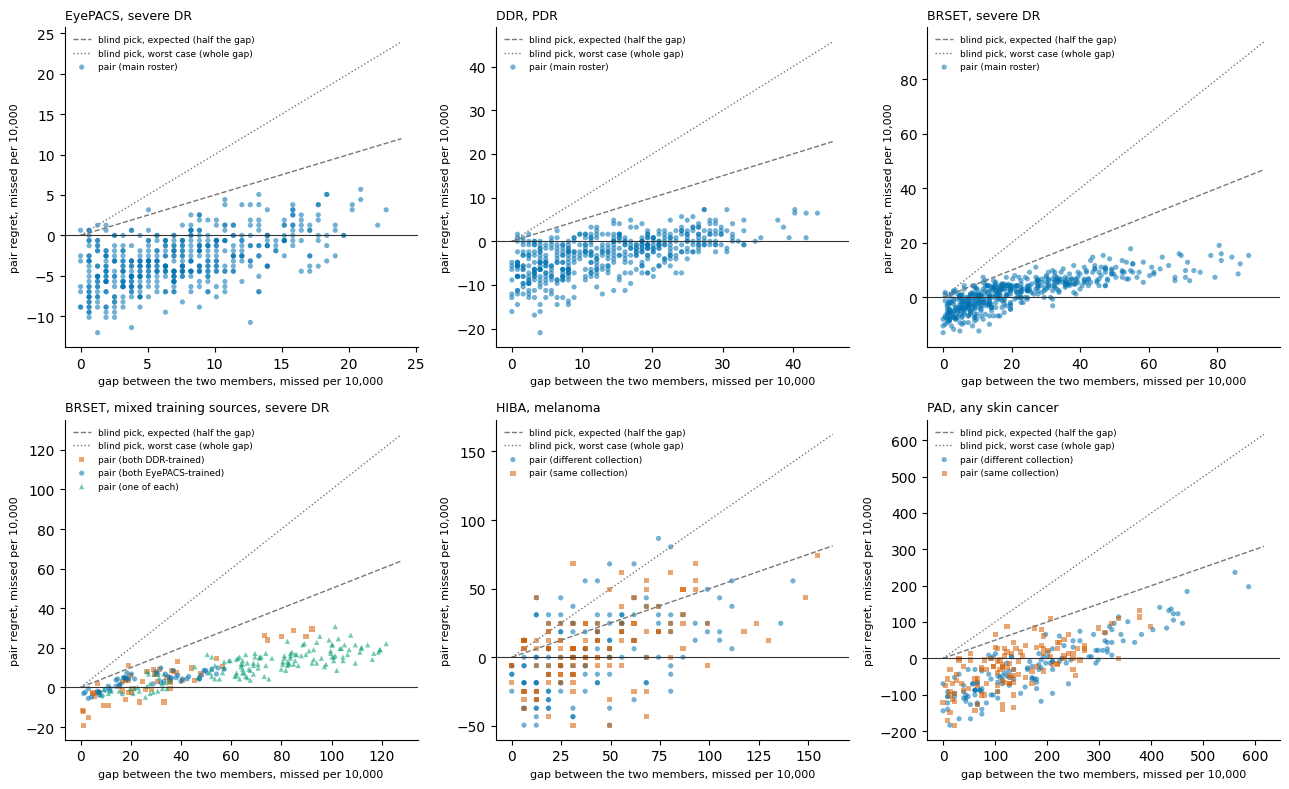

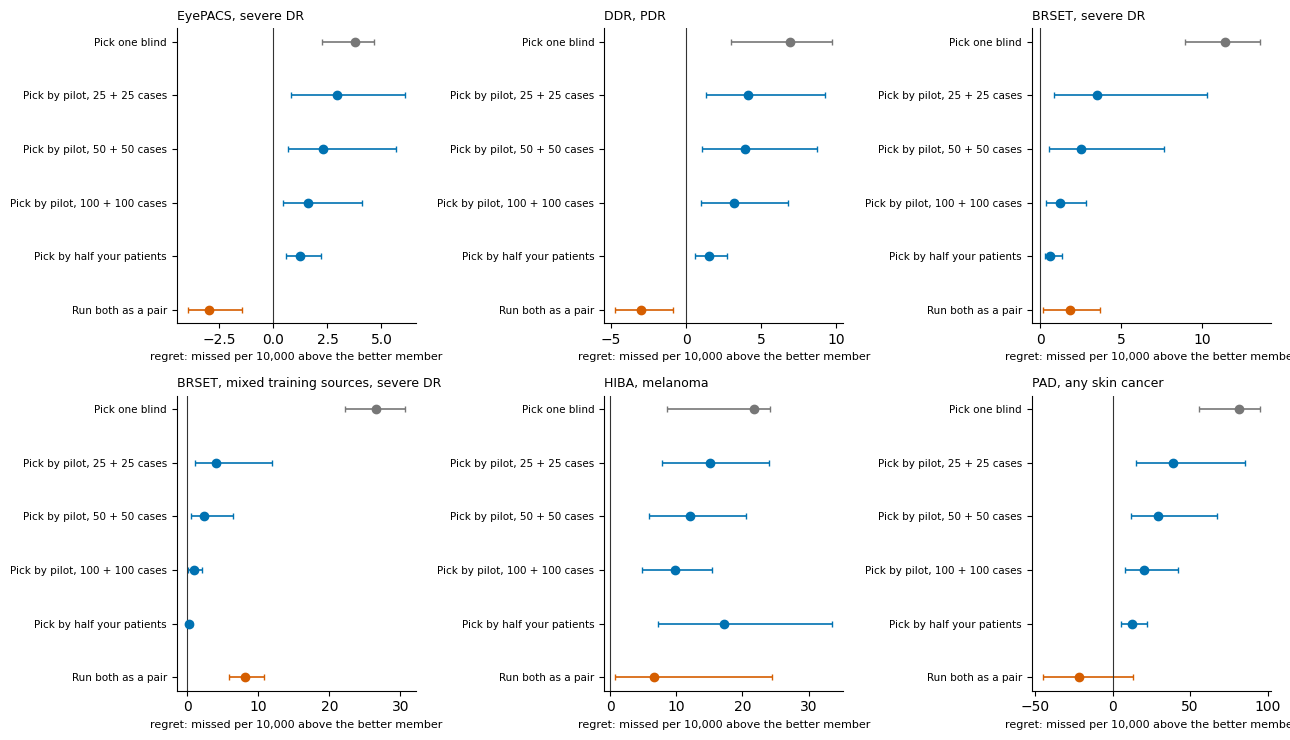

In [6]:
PANELS = ["EyePACS_severe", "DDR_pdr", "BRSET_severe", "BRSET_mixed_severe", "HIBA_mel", "PAD_mal"]
COL = {"main roster": "#0072B2", "both EyePACS-trained": "#0072B2", "both DDR-trained": "#D55E00", "one of each": "#009E73", "same collection": "#D55E00", "different collection": "#0072B2"}
MRK = {"main roster": "o", "both EyePACS-trained": "o", "both DDR-trained": "s", "one of each": "^", "same collection": "s", "different collection": "o"}
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for x_, key in zip(ax.flat, PANELS):
    d = PAIRS_DF[PAIRS_DF.roster == key]; mx = max(d.gap_per_10k.max(), 1e-9) * 1.05
    x_.plot([0, mx], [0, mx / 2], ls="--", color="#777", lw=1, label="blind pick, expected (half the gap)"); x_.plot([0, mx], [0, mx], ls=":", color="#777", lw=1, label="blind pick, worst case (whole gap)")
    x_.axhline(0, color="#333", lw=0.8)
    for t, g_ in d.groupby("pair_type"):
        x_.scatter(g_.gap_per_10k, g_.pair_regret_per_10k, s=14, alpha=0.55, color=COL[t], marker=MRK[t], edgecolors="none", label=f"pair ({t})")
    x_.set_title(RES[key]["full_sample"]["label"], loc="left", fontsize=9); x_.set_xlabel("gap between the two members, missed per 10,000", fontsize=8); x_.set_ylabel("pair regret, missed per 10,000", fontsize=8)
    [x_.spines[s].set_visible(False) for s in ("top", "right")]; x_.legend(fontsize=6.5, frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(f"{OUTD}/regret_c1_scatter.png", dpi=200); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(13, 7.5))
for x_, key in zip(ax.flat, PANELS):
    r = RES[key]; fs = r["full_sample"]["all"]; rows = [("Pick one blind", fs["blind_expected_regret"], "#777777")]
    for k, v in r["pilot"].items(): rows.append((f"Pick by pilot, {k} + {k} cases", v["all"]["pick"], "#0072B2"))
    rows.append(("Pick by half your patients", r["half_split"]["all"]["pick"], "#0072B2")); rows.append(("Run both as a pair", fs["pair_regret"], "#D55E00"))
    for i, (lab, (m, lo, hi), c) in enumerate(rows[::-1]):
        x_.errorbar(m, i, xerr=[[max(0, m - lo)], [max(0, hi - m)]], fmt="o", color=c, ms=6, capsize=2, lw=1.2)
    x_.set_yticks(range(len(rows))); x_.set_yticklabels([r_[0] for r_ in rows[::-1]], fontsize=7.5); x_.axvline(0, color="#333", lw=0.8)
    x_.set_title(r["full_sample"]["label"], loc="left", fontsize=9); x_.set_xlabel("regret: missed per 10,000 above the better member", fontsize=8)
    [x_.spines[s].set_visible(False) for s in ("top", "right")]
fig.tight_layout(); fig.savefig(f"{OUTD}/regret_c1_strategies.png", dpi=200); plt.show()

## Write the results record

In [7]:
REC = {"status": "post hoc, exploratory (review cycle 1 discussion); no lock", "written_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
       "bootstrap_resamples": B, "pilot_draws": DRAWS, "half_splits": NSPLIT, "results": RES, "input_sha256": HASHES}
def tolist(x): return {str(k): tolist(v) for k, v in x.items()} if isinstance(x, dict) else ([tolist(v) for v in x] if isinstance(x, (list, tuple)) else (x.tolist() if isinstance(x, np.ndarray) else x))
with open(OUT_JSON, "w") as fh: json.dump(tolist(REC), fh, indent=1, default=float)
PAIRS_DF.to_csv(OUT_CSV, index=False)
drive.flush_and_unmount(); drive.mount("/content/drive"); print("written", OUT_JSON, OUT_CSV)

Mounted at /content/drive
written /content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2/04_results/revisions_c1/regret_c1.json /content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2/04_results/revisions_c1/regret_c1_pairs.csv
